# Baseline Local Outlier Factor — IEEE-CIS Fraud Detection

## Objective

Fit a baseline `scikit-learn` **LocalOutlierFactor** with default parameters on the same
feature matrix used for the Isolation Forest baseline, then sanity-check the scores
against the labels.

`isFraud` is withheld from fitting; it is only used afterwards for evaluation.


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import LocalOutlierFactor

RNG_SEED = 42
np.random.seed(RNG_SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


## 1. Load data

In [2]:
DATA_DIR = "../../data/ieee-fraud-detection"

t0 = time.perf_counter()
tx = pd.read_csv(f"{DATA_DIR}/train_transaction.csv")
idt = pd.read_csv(f"{DATA_DIR}/train_identity.csv")
df = tx.merge(idt, on="TransactionID", how="left")
print(f"Loaded + merged in {time.perf_counter() - t0:.1f}s")
print(f"Merged shape: {df.shape}")


Loaded + merged in 10.6s
Merged shape: (590540, 434)


## 2. Data preparation

- Exclude `TransactionID` (identifier), `isFraud` (label), `TransactionDT` (timestamp).
- Drop columns missing in more than 90% of rows.
- Median imputation for numeric columns, simple ordinal (label) encoding for categorical
  columns.


In [3]:
EXCLUDE_COLS = ["TransactionID", "isFraud", "TransactionDT"]
MISSING_DROP_THRESHOLD = 0.90

y = df["isFraud"].copy()  # withheld from fitting; evaluation only

missing_pct = df.isna().mean()
cols_to_drop_missing = missing_pct[missing_pct > MISSING_DROP_THRESHOLD].index.tolist()
print(f"Dropping {len(cols_to_drop_missing)} columns with >{MISSING_DROP_THRESHOLD:.0%} missing")

work = df.drop(columns=EXCLUDE_COLS + cols_to_drop_missing)

numeric_cols = [c for c in work.columns if pd.api.types.is_numeric_dtype(work[c])]
categorical_cols = [c for c in work.columns if c not in numeric_cols]

X = work.copy()
X[numeric_cols] = X[numeric_cols].fillna(X[numeric_cols].median())
for col in categorical_cols:
    X[col] = pd.factorize(X[col].fillna("missing"))[0]

assert X.isna().sum().sum() == 0
assert X.shape == (590540, 419)
print(f"Feature matrix: {X.shape} "
      f"({len(numeric_cols)} numeric, {len(categorical_cols)} ordinal-encoded categorical)")


Dropping 12 columns with >90% missing


Feature matrix: (590540, 419) (390 numeric, 29 ordinal-encoded categorical)


## 3. Baseline LocalOutlierFactor (default parameters)

In [4]:
FIT_SIZE = 25000  # None = fit on every row

if FIT_SIZE is None:
    fit_idx = np.arange(len(X))
else:
    fit_idx = np.random.default_rng(RNG_SEED).choice(len(X), size=FIT_SIZE, replace=False)
X_fit, y_fit = X.iloc[fit_idx], y.iloc[fit_idx].values

t0 = time.perf_counter()
lof = LocalOutlierFactor()  # defaults: n_neighbors=20, contamination="auto", metric="minkowski"
lof.fit(X_fit)
print(f"Fit on {len(X_fit):,} rows in {time.perf_counter() - t0:.1f}s")

# LOF ~ 1: as dense as its neighbours (inlier); >> 1: much sparser than its neighbours.
scores = -lof.negative_outlier_factor_
print(f"LOF score range: [{scores.min():.3f}, {scores.max():.3f}], "
      f"median {np.median(scores):.3f}")


Fit on 25,000 rows in 2.3s
LOF score range: [0.943, 73.357], median 1.135


## 4. Score distribution

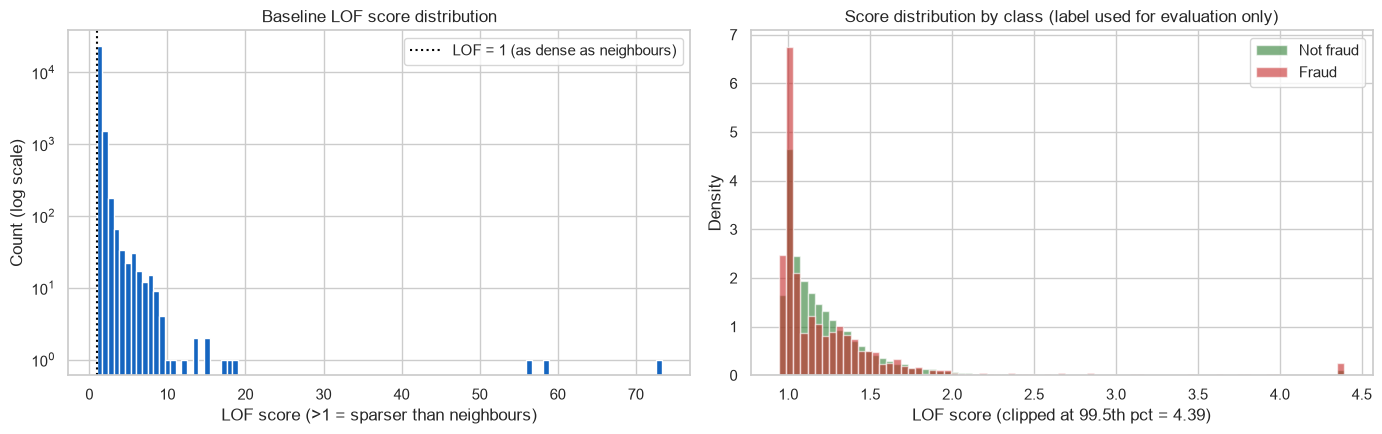

Mean score -- fraud: 1.284, non-fraud: 1.264
Median score -- fraud: 1.080, non-fraud: 1.136


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(scores, bins=100, color="#1565C0")
axes[0].set_yscale("log")
axes[0].axvline(1, color="black", linestyle=":", label="LOF = 1 (as dense as neighbours)")
axes[0].set_xlabel("LOF score (>1 = sparser than neighbours)")
axes[0].set_ylabel("Count (log scale)")
axes[0].set_title("Baseline LOF score distribution")
axes[0].legend()

hi = np.quantile(scores, 0.995)  # clip the extreme tail so the bulk is visible
bins = np.linspace(scores.min(), hi, 80)
axes[1].hist(np.clip(scores[y_fit == 0], None, hi), bins=bins, density=True, alpha=0.6,
             color="#2E7D32", label="Not fraud")
axes[1].hist(np.clip(scores[y_fit == 1], None, hi), bins=bins, density=True, alpha=0.6,
             color="#C62828", label="Fraud")
axes[1].set_xlabel(f"LOF score (clipped at 99.5th pct = {hi:.2f})")
axes[1].set_ylabel("Density")
axes[1].set_title("Score distribution by class (label used for evaluation only)")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Mean score -- fraud: {scores[y_fit == 1].mean():.3f}, "
      f"non-fraud: {scores[y_fit == 0].mean():.3f}")
print(f"Median score -- fraud: {np.median(scores[y_fit == 1]):.3f}, "
      f"non-fraud: {np.median(scores[y_fit == 0]):.3f}")


**Findings:** the scores form a tight bulk just above 1 (median 1.135) with a long thin right tail out to ~73, so a handful of points are far sparser than their neighbours. Fraud and non-fraud overlap almost completely, and fraud's *median* score is actually slightly lower (1.080 vs. 1.136). Features are unscaled, so Euclidean distance is dominated by large-magnitude columns (e.g. `TransactionAmt`, some `V` columns), which limits what 'local density' means here.

### LOF score surface (UMAP layout)

The histograms above hide *where* high LOF scores sit in feature space. This reproduces the Isolation Forest notebook's UMAP so the two methods can be compared point for point


In [7]:
import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Same subsample as the Isolation Forest notebook (N_VIZ=30000, rng seed 42 over df.index)
N_VIZ = 30000
viz_idx = np.random.default_rng(RNG_SEED).choice(df.index, size=N_VIZ, replace=False)

X_viz = X.loc[viz_idx]
viz_fraud = y.loc[viz_idx].values

X_viz_scaled = StandardScaler().fit_transform(X_viz)
pca_pre = PCA(n_components=50, random_state=RNG_SEED)
X_viz_pca50 = pca_pre.fit_transform(X_viz_scaled)
print(f"Visualization subsample: {N_VIZ:,} rows")
print(f"PCA pre-reduction: {X_viz.shape[1]} -> 50 components, "
      f"explaining {pca_pre.explained_variance_ratio_.sum() * 100:.1f}% of variance")

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=RNG_SEED)
embedding = reducer.fit_transform(X_viz_pca50)
print(f"UMAP embedding shape: {embedding.shape}")

# Baseline LOF (defaults) fit on the visualization rows so every plotted point has a score
viz_scores = -LocalOutlierFactor().fit(X_viz).negative_outlier_factor_
print(f"Viz LOF score range: [{viz_scores.min():.3f}, {viz_scores.max():.3f}], "
      f"median {np.median(viz_scores):.3f}")


/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Visualization subsample: 30,000 rows
PCA pre-reduction: 419 -> 50 components, explaining 80.9% of variance


/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (30000, 2)


Viz LOF score range: [0.942, 59.308], median 1.131


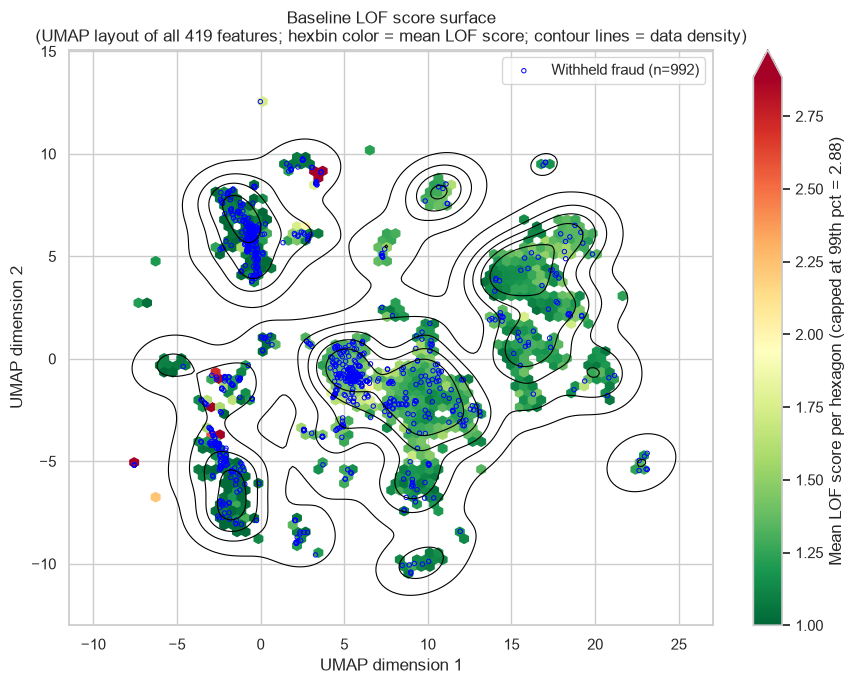

In [21]:
vmax = np.quantile(viz_scores, 0.99)  # cap the colour scale; the raw max (~73) would flatten everything else

fig, ax = plt.subplots(figsize=(9, 7))
hb = ax.hexbin(embedding[:, 0], embedding[:, 1], C=viz_scores, reduce_C_function=np.mean,
               gridsize=60, cmap="RdYlGn_r", mincnt=5, vmin=1, vmax=vmax)
plt.colorbar(hb, ax=ax, extend="max",
             label=f"Mean LOF score per hexagon (capped at 99th pct = {vmax:.2f})")

sns.kdeplot(x=embedding[:, 0], y=embedding[:, 1], levels=6, color="black", linewidths=0.8, ax=ax)

fraud_mask = viz_fraud == 1
ax.scatter(embedding[fraud_mask, 0], embedding[fraud_mask, 1], s=10, facecolors="none",
           edgecolors="blue", linewidths=0.7, label=f"Withheld fraud (n={fraud_mask.sum()})")

ax.set_xlabel("UMAP dimension 1")
ax.set_ylabel("UMAP dimension 2")
ax.set_title("Baseline LOF score surface\n"
             "(UMAP layout of all 419 features; hexbin color = mean LOF score; "
             "contour lines = data density)")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


## 5. Sanity check against labels

In [5]:
base_rate = y_fit.mean()
auc = roc_auc_score(y_fit, scores)
print(f"Fraud base rate in fitted rows: {base_rate:.3%}")
print(f"ROC-AUC: {auc:.4f}\n")

order = np.argsort(-scores)
for label, k in [("top 10", 10), ("top 3.5%", int(round(0.035 * len(scores))))]:
    hits = int(y_fit[order[:k]].sum())
    print(f"{label:>9} (k={k:,}): {hits:,} fraud, precision {hits / k:.2%}, "
          f"lift {hits / k / base_rate:.2f}x vs. base rate, "
          f"recall {hits / y_fit.sum():.2%}")


Fraud base rate in fitted rows: 3.284%
ROC-AUC: 0.4563

   top 10 (k=10): 0 fraud, precision 0.00%, lift 0.00x vs. base rate, recall 0.00%
 top 3.5% (k=875): 41 fraud, precision 4.69%, lift 1.43x vs. base rate, recall 4.99%


**Findings:** ROC-AUC is **0.456**, below 0.5 and well below the Isolation Forest baseline (0.77): the default LOF ranking is no better than random for fraud. None of the top 10 is fraud. The top 3.5% contains 41 frauds (4.69% precision, 1.43x lift), a small gain over the 3.28% base rate that is not supported by the overall AUC. Fraud here does not appear as a local density outlier on raw, unscaled features. 

## 6. Tuning `n_neighbors` (the paper's MinPts)

`n_neighbors` is the only essential LOF parameter. The sweep below refits LOF for `n_neighbors` on a log10 grid from 10 to 10,000 (the default of 20 is included). Each fit is scored on the continuous LOF score with ROC-AUC and PR-AUC (average precision). Labels are used for evaluation only.

The paper also suggests taking each point's **maximum** LOF over a range of MinPts values; that variant is computed from the same fits at no extra cost.

In [5]:
from sklearn.metrics import average_precision_score

# log10-spaced grid, 10 .. 10,000 (capped by the 25,000-row fit sample), plus the default k=20
K_GRID = sorted(set(np.round(np.logspace(1, 4, 13)).astype(int).tolist() + [20]))
assert max(K_GRID) < len(X_fit)
print("K_GRID:", K_GRID)

sweep_scores = {}  # ~4 GB peak at k=10,000; fine on 16 GB
rows = []
for k in K_GRID:
    t0 = time.perf_counter()
    m = LocalOutlierFactor(n_neighbors=k).fit(X_fit)
    s = -m.negative_outlier_factor_
    sweep_scores[k] = s
    rows.append({
        "n_neighbors": k,
        "roc_auc": roc_auc_score(y_fit, s),
        "pr_auc": average_precision_score(y_fit, s),
        "fit_seconds": time.perf_counter() - t0,
    })
    print(f"k={k:>3}: ROC-AUC {rows[-1]['roc_auc']:.4f}, PR-AUC {rows[-1]['pr_auc']:.4f} "
          f"({rows[-1]['fit_seconds']:.1f}s)")

sweep = pd.DataFrame(rows).set_index("n_neighbors")

# Paper's heuristic: per-point max LOF over the whole range of k
max_scores = np.max(np.vstack(list(sweep_scores.values())), axis=0)
max_auc = roc_auc_score(y_fit, max_scores)
max_pr = average_precision_score(y_fit, max_scores)
print(f"\nMax-over-k LOF (k={K_GRID[0]}..{K_GRID[-1]}): ROC-AUC {max_auc:.4f}, PR-AUC {max_pr:.4f}")

K_GRID: [10, 18, 20, 32, 56, 100, 178, 316, 562, 1000, 1778, 3162, 5623, 10000]


k= 10: ROC-AUC 0.4719, PR-AUC 0.0345 (3.3s)


k= 18: ROC-AUC 0.4592, PR-AUC 0.0333 (3.8s)


k= 20: ROC-AUC 0.4563, PR-AUC 0.0330 (3.8s)


k= 32: ROC-AUC 0.4542, PR-AUC 0.0335 (3.9s)


k= 56: ROC-AUC 0.4633, PR-AUC 0.0353 (4.1s)


... (5 outputs left out)

k=1778: ROC-AUC 0.7156, PR-AUC 0.0656 (10.5s)


k=3162: ROC-AUC 0.7200, PR-AUC 0.0683 (14.4s)


k=5623: ROC-AUC 0.6951, PR-AUC 0.0648 (21.1s)


k=10000: ROC-AUC 0.6784, PR-AUC 0.0635 (35.8s)

Max-over-k LOF (k=10..10000): ROC-AUC 0.7310, PR-AUC 0.0683


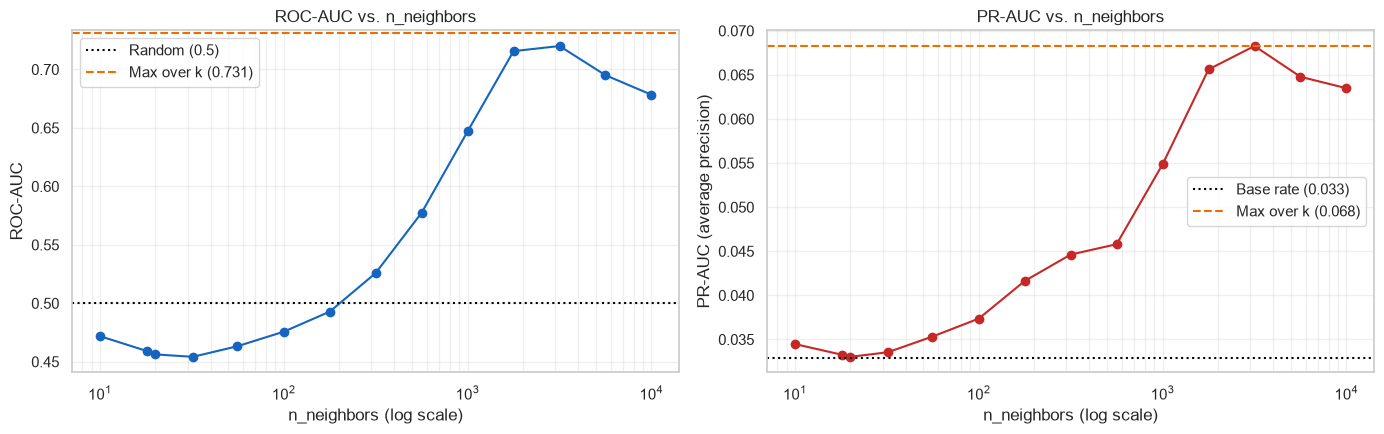

Best ROC-AUC: 0.7200 at n_neighbors=3162 (default k=20: 0.4563)
Best PR-AUC:  0.0683 at n_neighbors=3162 (default k=20: 0.0330)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(sweep.index, sweep["roc_auc"], marker="o", color="#1565C0")
axes[0].axhline(0.5, color="black", linestyle=":", label="Random (0.5)")
axes[0].axhline(max_auc, color="#EF6C00", linestyle="--", label=f"Max over k ({max_auc:.3f})")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("ROC-AUC vs. n_neighbors")

axes[1].plot(sweep.index, sweep["pr_auc"], marker="o", color="#C62828")
axes[1].axhline(y_fit.mean(), color="black", linestyle=":", label=f"Base rate ({y_fit.mean():.3f})")
axes[1].axhline(max_pr, color="#EF6C00", linestyle="--", label=f"Max over k ({max_pr:.3f})")
axes[1].set_ylabel("PR-AUC (average precision)")
axes[1].set_title("PR-AUC vs. n_neighbors")

for ax in axes:
    ax.set_xscale("log")
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlabel("n_neighbors (log scale)")
    ax.legend()
plt.tight_layout()
plt.show()

best_k = sweep["roc_auc"].idxmax()
print(f"Best ROC-AUC: {sweep.loc[best_k, 'roc_auc']:.4f} at n_neighbors={best_k} "
      f"(default k=20: {sweep.loc[20, 'roc_auc']:.4f})")
best_k_pr = sweep["pr_auc"].idxmax()
print(f"Best PR-AUC:  {sweep.loc[best_k_pr, 'pr_auc']:.4f} at n_neighbors={best_k_pr} "
      f"(default k=20: {sweep.loc[20, 'pr_auc']:.4f})")

**Findings:** ROC-AUC rises from 0.456 at the default `k=20` to a peak of **0.720 at `k=3162`** (PR-AUC 0.068, about 2.1x the 0.033 base rate), then declines (0.695 at 5,623, 0.678 at 10,000). PR-AUC peaks at the same `k`. Very small `k` is worst because local density estimates are noisy and fraud is not a tiny, isolated cluster. Very large `k` washes out the notion of 'local'. The best `k` is roughly 13% of the 25,000-row fit sample, so it likely scales with sample size and should be re-tuned if `FIT_SIZE` changes. 

## 7. LOF at the best `n_neighbors`

This section uses the label-based optimum from the sweep (`best_k`, the `n_neighbors` with the highest ROC-AUC) and repeats the UMAP score surface from above with it. The layout is identical (same 30,000-row subsample, same PCA -> UMAP embedding); only the LOF scores change. The right panel marks the top 3.5% highest-scoring rows, the same cut-off as in section 5.

n_neighbors=3162: viz LOF score range [0.961, 325.236], median 1.021
ROC-AUC on the viz subsample: 0.7216 (baseline k=20: 0.4535)


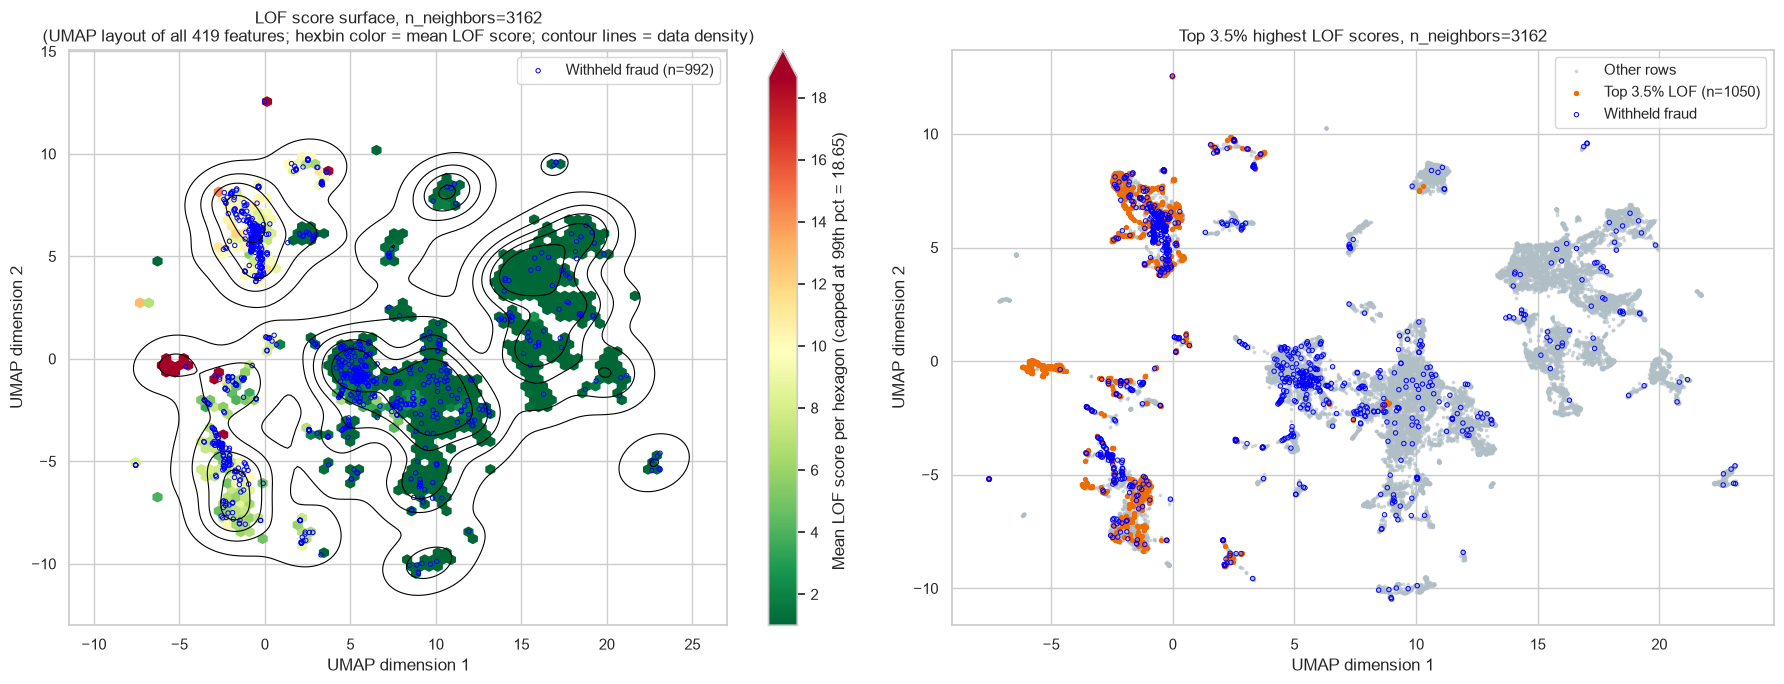

In [8]:
BEST_K = int(best_k)
TOP_FRAC = 0.035

# Same visualization rows as the baseline UMAP; only n_neighbors changes
viz_scores_best = -LocalOutlierFactor(n_neighbors=BEST_K).fit(X_viz).negative_outlier_factor_
print(f"n_neighbors={BEST_K}: viz LOF score range "
      f"[{viz_scores_best.min():.3f}, {viz_scores_best.max():.3f}], median {np.median(viz_scores_best):.3f}")
print(f"ROC-AUC on the viz subsample: {roc_auc_score(viz_fraud, viz_scores_best):.4f} "
      f"(baseline k=20: {roc_auc_score(viz_fraud, viz_scores):.4f})")

vmax = np.quantile(viz_scores_best, 0.99)
fraud_mask = viz_fraud == 1
top_mask = viz_scores_best >= np.quantile(viz_scores_best, 1 - TOP_FRAC)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ax = axes[0]
hb = ax.hexbin(embedding[:, 0], embedding[:, 1], C=viz_scores_best, reduce_C_function=np.mean,
               gridsize=60, cmap="RdYlGn_r", mincnt=5, vmin=1, vmax=vmax)
plt.colorbar(hb, ax=ax, extend="max",
             label=f"Mean LOF score per hexagon (capped at 99th pct = {vmax:.2f})")
sns.kdeplot(x=embedding[:, 0], y=embedding[:, 1], levels=6, color="black", linewidths=0.8, ax=ax)
ax.scatter(embedding[fraud_mask, 0], embedding[fraud_mask, 1], s=10, facecolors="none",
           edgecolors="blue", linewidths=0.7, label=f"Withheld fraud (n={fraud_mask.sum()})")
ax.set_title(f"LOF score surface, n_neighbors={BEST_K}\n"
             "(UMAP layout of all 419 features; hexbin color = mean LOF score; "
             "contour lines = data density)")
ax.legend(loc="best")

ax = axes[1]
ax.scatter(embedding[~top_mask, 0], embedding[~top_mask, 1], s=3, color="#B0BEC5", alpha=0.5,
           label="Other rows")
ax.scatter(embedding[top_mask, 0], embedding[top_mask, 1], s=8, color="#EF6C00",
           label=f"Top {TOP_FRAC:.1%} LOF (n={top_mask.sum()})")
ax.scatter(embedding[fraud_mask, 0], embedding[fraud_mask, 1], s=10, facecolors="none",
           edgecolors="blue", linewidths=0.7, label="Withheld fraud")
ax.set_title(f"Top {TOP_FRAC:.1%} highest LOF scores, n_neighbors={BEST_K}")
ax.legend(loc="best")

for ax in axes:
    ax.set_xlabel("UMAP dimension 1")
    ax.set_ylabel("UMAP dimension 2")
plt.tight_layout()
plt.show()

In [9]:
def top_slice_report(name, score, y_true, n_top=10, frac=TOP_FRAC):
    """Fraud rate in the top-n and top-frac slices of the LOF ranking."""
    base = y_true.mean()
    order = np.argsort(-score)
    out = []
    for label, k in [(f"top {n_top}", n_top), (f"top {frac:.1%}", int(round(frac * len(score))))]:
        hits = int(y_true[order[:k]].sum())
        out.append({"data": name, "slice": label, "n": k, "fraud": hits,
                    "fraud_rate": hits / k, "lift": hits / k / base,
                    "recall": hits / y_true.sum(), "min_score": score[order[k - 1]]})
    return out

rows = []
# 25,000-row fit sample (same rows as section 5): baseline vs. best k
rows += top_slice_report(f"fit sample, k=20", sweep_scores[20], y_fit)
rows += top_slice_report(f"fit sample, k={BEST_K}", sweep_scores[BEST_K], y_fit)
# 30,000-row UMAP subsample
rows += top_slice_report(f"UMAP subsample, k={BEST_K}", viz_scores_best, viz_fraud)

report = pd.DataFrame(rows)
print(f"Base fraud rate -- fit sample: {y_fit.mean():.3%}, UMAP subsample: {viz_fraud.mean():.3%}\n")
print(report.to_string(index=False, formatters={
    "fraud_rate": "{:.2%}".format, "lift": "{:.2f}x".format,
    "recall": "{:.2%}".format, "min_score": "{:.2f}".format}))

# What do the top-10 rows look like on the fit sample?
top10 = np.argsort(-sweep_scores[BEST_K])[:10]
print("\nTop-10 rows on the fit sample (k=%d):" % BEST_K)
print(pd.DataFrame({"LOF": sweep_scores[BEST_K][top10], "isFraud": y_fit[top10],
                    "TransactionAmt": X_fit["TransactionAmt"].values[top10]}).round(2).to_string())

Base fraud rate -- fit sample: 3.284%, UMAP subsample: 3.307%

                  data    slice    n  fraud fraud_rate  lift recall min_score
      fit sample, k=20   top 10   10      0      0.00% 0.00x  0.00%     13.36
      fit sample, k=20 top 3.5%  875     41      4.69% 1.43x  4.99%      1.93
    fit sample, k=3162   top 10   10      0      0.00% 0.00x  0.00%    235.35
    fit sample, k=3162 top 3.5%  875     65      7.43% 2.26x  7.92%     24.20
UMAP subsample, k=3162   top 10   10      0      0.00% 0.00x  0.00%    253.64
UMAP subsample, k=3162 top 3.5% 1050     75      7.14% 2.16x  7.56%     15.17

Top-10 rows on the fit sample (k=3162):
      LOF  isFraud  TransactionAmt
0  295.17        0            75.0
1  271.18        0            50.0
2  269.67        0           150.0
3  256.62        0            25.0
4  252.71        0           100.0
5  243.99        0            30.0
6  237.89        0            30.0
7  236.04        0           100.0
8  235.35        0            20.0


**Findings:**

- **UMAP surface.** With `n_neighbors=3162` the score surface is very different from the baseline. Most of the large dense blobs are green (LOF about 1), and the high scores concentrate in a few small, isolated islands on the left of the map, with most of the fraud also sitting in those islands. The top 3.5% (orange, right panel) overlaps heavily with the left-hand fraud-rich clusters, which is where the extra ROC-AUC comes from. One isolated island near (-5, 0) is dark red but contains no fraud: LOF flags it for being sparse, not for being fraudulent.
- **Top 3.5%.** On the 25,000-row fit sample, 65 of 875 rows are fraud: **7.43% precision, 2.26x lift, 7.9% recall**, up from 4.69% / 1.43x / 5.0% at the default `k=20`. The independent 30,000-row UMAP subsample gives a consistent 7.14% (2.16x).
- **Top 10.** 0 of 10 are fraud (also 0 of 10 at `k=20`). The very highest LOF scores are not where fraud is concentrated.